In [5]:
import importlib.util

if importlib.util.find_spec("ultralytics") is None:
    %pip install ultralytics
else:
    print("Ultralytics já está instalado no kernel.")

Ultralytics já está instalado no kernel.


In [6]:
import cv2
import numpy as np
import torch
from PIL import Image, ImageEnhance, ImageOps, ImageStat
from ultralytics import YOLO

print(f"OpenCV: {cv2.__version__}")
print(f"Pillow: {Image.__version__}")
print(f"PyTorch: {torch.__version__}")

OpenCV: 5.0.0
Pillow: 11.1.0
PyTorch: 2.14.0+cpu


# Treinamento YOLOv8 de segmentação com dataset_model

In [10]:
import hashlib
import json
import math
import random
import re
from collections import Counter
from pathlib import Path

PASTA_BASE = Path.cwd()
PASTA_ORIGEM = PASTA_BASE / "dataset_model"
PASTA_IMAGENS_ORIGEM = PASTA_ORIGEM / "images"
PASTA_LABELS_ORIGEM = PASTA_ORIGEM / "labels"
PASTA_DATASET = PASTA_BASE / "dataset_model_yolo"
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff", ".avif"}
SEMENTE = 42
PROPORCAO_VALIDACAO = 0.2
ANGULOS_ROTACAO = (-10, 10)
LIMIAR_BRILHO = 90
ALVO_BRILHO = 120
FATOR_MAXIMO_BRILHO = 2.2

if not PASTA_IMAGENS_ORIGEM.is_dir() or not PASTA_LABELS_ORIGEM.is_dir():
    raise FileNotFoundError(f"Dataset de origem nao encontrado: {PASTA_ORIGEM}")
if PASTA_DATASET.exists():
    print("Destino ja existe; os arquivos gerados por esta preparacao serao atualizados.")


def converter_shape_para_poligono(shape):
    tipo = shape.get("shape_type")
    pontos = [(float(x), float(y)) for x, y in shape.get("points", [])]
    if tipo == "polygon" and len(pontos) >= 3:
        return pontos
    if tipo == "rectangle":
        if len(pontos) == 4:
            return pontos
        if len(pontos) == 2:
            (x1, y1), (x2, y2) = pontos
            return [(x1, y1), (x2, y1), (x2, y2), (x1, y2)]
    if tipo == "circle" and len(pontos) == 2:
        (cx, cy), (px, py) = pontos
        raio = math.hypot(px - cx, py - cy)
        if raio > 0:
            return [
                (cx + raio * math.cos(2 * math.pi * i / 32),
                 cy + raio * math.sin(2 * math.pi * i / 32))
                for i in range(32)
            ]
    raise ValueError(f"Anotacao invalida ou nao suportada: {tipo!r}")


def codificar_poligonos_yolo(poligonos, largura, altura):
    linhas = []
    for poligono in poligonos:
        valores = []
        for x, y in poligono:
            valores.extend((
                min(1.0, max(0.0, x / largura)),
                min(1.0, max(0.0, y / altura)),
            ))
        if len(valores) >= 6:
            linhas.append("0 " + " ".join(f"{valor:.6f}" for valor in valores))
    return "\n".join(linhas)


def girar_imagem_e_poligonos(imagem, poligonos, angulo):
    array = np.asarray(imagem)
    altura, largura = array.shape[:2]
    centro = (largura / 2, altura / 2)
    matriz = cv2.getRotationMatrix2D(centro, angulo, 1.0)
    cosseno, seno = abs(matriz[0, 0]), abs(matriz[0, 1])
    nova_largura = int(math.ceil(altura * seno + largura * cosseno))
    nova_altura = int(math.ceil(altura * cosseno + largura * seno))
    matriz[0, 2] += nova_largura / 2 - centro[0]
    matriz[1, 2] += nova_altura / 2 - centro[1]
    array_girado = cv2.warpAffine(
        array, matriz, (nova_largura, nova_altura),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(114, 114, 114),
    )
    poligonos_girados = []
    for poligono in poligonos:
        pontos = np.asarray(poligono, dtype=np.float32)
        girados = pontos @ matriz[:, :2].T + matriz[:, 2]
        poligonos_girados.append([tuple(ponto) for ponto in girados])
    return Image.fromarray(array_girado), poligonos_girados


def salvar_amostra(split, nome, imagem, poligonos):
    pasta_images = PASTA_DATASET / "images" / split
    pasta_labels = PASTA_DATASET / "labels" / split
    imagem.save(pasta_images / f"{nome}.jpg", format="JPEG", quality=95)
    rotulos = codificar_poligonos_yolo(poligonos, imagem.width, imagem.height)
    (pasta_labels / f"{nome}.txt").write_text(rotulos, encoding="utf-8")


registros = []
contagem_shapes = Counter()
for pasta_categoria in sorted(path for path in PASTA_IMAGENS_ORIGEM.iterdir() if path.is_dir()):
    pasta_labels_categoria = PASTA_LABELS_ORIGEM / pasta_categoria.name
    if not pasta_labels_categoria.is_dir():
        raise FileNotFoundError(f"Labels nao encontradas: {pasta_labels_categoria}")

    for arquivo_json in sorted(pasta_labels_categoria.glob("*.json")):
        dados = json.loads(arquivo_json.read_text(encoding="utf-8"))
        nome_imagem = Path(str(dados.get("imagePath", "")).replace("\\", "/")).name
        caminho_imagem = pasta_categoria / nome_imagem
        if not nome_imagem or not caminho_imagem.is_file():
            raise FileNotFoundError(f"Imagem correspondente nao encontrada para {arquivo_json}")

        poligonos = []
        for shape in dados.get("shapes", []):
            if not str(shape.get("label", "")).strip():
                raise ValueError(f"Anotacao sem label em {arquivo_json.name}")
            poligonos.append(converter_shape_para_poligono(shape))
            contagem_shapes[shape.get("shape_type", "missing")] += 1

        with Image.open(caminho_imagem) as imagem_origem:
            imagem = imagem_origem.convert("RGB")
            brilho = ImageStat.Stat(imagem.convert("L")).mean[0]

        slug_categoria = re.sub(r"[^A-Za-z0-9_-]+", "_", pasta_categoria.name).strip("_") or "categoria"
        hash_nome = hashlib.sha1(
            f"{pasta_categoria.name}/{caminho_imagem.name}".encode("utf-8")
        ).hexdigest()[:12]
        nome_base = f"{slug_categoria[:18]}_{hash_nome}"
        registros.append({
            "categoria": pasta_categoria.name,
            "imagem": caminho_imagem,
            "poligonos": poligonos,
            "brilho": brilho,
            "nome_base": nome_base,
        })

if len(registros) < 2:
    raise ValueError("Sao necessarias pelo menos duas imagens rotuladas.")

aleatorio = random.Random(SEMENTE)
treino, validacao = [], []
for categoria in sorted({registro["categoria"] for registro in registros}):
    grupo = [registro for registro in registros if registro["categoria"] == categoria]
    aleatorio.shuffle(grupo)
    quantidade_validacao = max(1, round(len(grupo) * PROPORCAO_VALIDACAO))
    validacao.extend(grupo[:quantidade_validacao])
    treino.extend(grupo[quantidade_validacao:])

for split in ("train", "val"):
    (PASTA_DATASET / "images" / split).mkdir(parents=True, exist_ok=True)
    (PASTA_DATASET / "labels" / split).mkdir(parents=True, exist_ok=True)

variantes = Counter()
imagens_escuras = sum(registro["brilho"] < LIMIAR_BRILHO for registro in registros)
imagens_sem_objetos = sum(not registro["poligonos"] for registro in registros)
for split, conjunto in (("train", treino), ("val", validacao)):
    for registro in conjunto:
        with Image.open(registro["imagem"]) as imagem_origem:
            imagem = imagem_origem.convert("RGB")
        poligonos = registro["poligonos"]
        nome_base = registro["nome_base"]

        salvar_amostra(split, f"{nome_base}_original", imagem, poligonos)
        variantes[f"{split}_original"] += 1
        if split != "train":
            continue

        imagem_flip = ImageOps.mirror(imagem)
        poligonos_flip = [[(imagem.width - x, y) for x, y in poligono] for poligono in poligonos]
        salvar_amostra(split, f"{nome_base}_flip", imagem_flip, poligonos_flip)
        variantes["flip_horizontal"] += 1

        for angulo in ANGULOS_ROTACAO:
            imagem_girada, poligonos_girados = girar_imagem_e_poligonos(imagem, poligonos, angulo)
            sufixo = f"rot_{'p' if angulo > 0 else 'm'}{abs(angulo)}"
            salvar_amostra(split, f"{nome_base}_{sufixo}", imagem_girada, poligonos_girados)
            variantes["rotacao"] += 1

        if registro["brilho"] < LIMIAR_BRILHO:
            fator = min(FATOR_MAXIMO_BRILHO, ALVO_BRILHO / max(registro["brilho"], 1))
            imagem_clareada = ImageEnhance.Brightness(imagem).enhance(fator)
            salvar_amostra(split, f"{nome_base}_clareada", imagem_clareada, poligonos)
            variantes["clareada"] += 1

conteudo_yaml = (
    f'path: "{PASTA_DATASET.as_posix()}"\n'
    "train: images/train\n"
    "val: images/val\n\n"
    "names:\n"
    "  0: lixo\n"
)
(PASTA_DATASET / "dataset.yaml").write_text(conteudo_yaml, encoding="utf-8")

print(f"Imagens de origem: {len(registros)}; sem objetos anotados: {imagens_sem_objetos}")
print(f"Originais no treino: {len(treino)} | originais na validacao: {len(validacao)}")
print(f"Variantes geradas: {dict(variantes)}")
print(f"Imagens escuras (< {LIMIAR_BRILHO}/255): {imagens_escuras}; clareadas no treino: {variantes['clareada']}")
print(f"Anotacoes convertidas: {dict(contagem_shapes)}")
print(f"Dataset YOLO pronto em: {PASTA_DATASET}")

Destino ja existe; os arquivos gerados por esta preparacao serao atualizados.
Imagens de origem: 311; sem objetos anotados: 2
Originais no treino: 248 | originais na validacao: 63
Variantes geradas: {'train_original': 248, 'flip_horizontal': 248, 'rotacao': 496, 'clareada': 55, 'val_original': 63}
Imagens escuras (< 90/255): 72; clareadas no treino: 55
Anotacoes convertidas: {'polygon': 860, 'circle': 4, 'rectangle': 11}
Dataset YOLO pronto em: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo


## Treinamento do modelo

In [9]:
import os
from pathlib import Path

import torch
from ultralytics import YOLO

PASTA_BASE = Path.cwd()
PASTA_DATASET = PASTA_BASE / "dataset_model_yolo"
SEMENTE = 42
if not (PASTA_DATASET / "dataset.yaml").is_file():
    raise FileNotFoundError(
        f"Dataset YOLO nao encontrado em {PASTA_DATASET}. Execute primeiro a celula de preparacao."
    )

DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 0 if os.name == "nt" else 2


def treinar_modelo_teste02():
    modelo = YOLO("yolov8n-seg.pt")
    resultados = modelo.train(
        data=str(PASTA_DATASET / "dataset.yaml"),
        epochs=50,
        imgsz=512,
        batch=4,
        workers=WORKERS,
        project=str(PASTA_BASE / "runs" / "segment"),
        name="teste02_dataset_model",
        degrees=0.0,
        fliplr=0.0,
        mosaic=0.0,
        hsv_v=0.10,
        save=True,
        plots=True,
        device=DEVICE,
        seed=SEMENTE,
    )
    melhor_peso = Path(resultados.save_dir) / "weights" / "best.pt"
    print("Treinamento do teste02 concluido.")
    print(f"Dispositivo: {DEVICE} | workers: {WORKERS}")
    print(f"Melhores pesos: {melhor_peso}")
    return resultados


resultados_treino = treinar_modelo_teste02()

Ultralytics 8.4.182  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo\dataset.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.1, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937,

## Teste visual no conjunto de validação

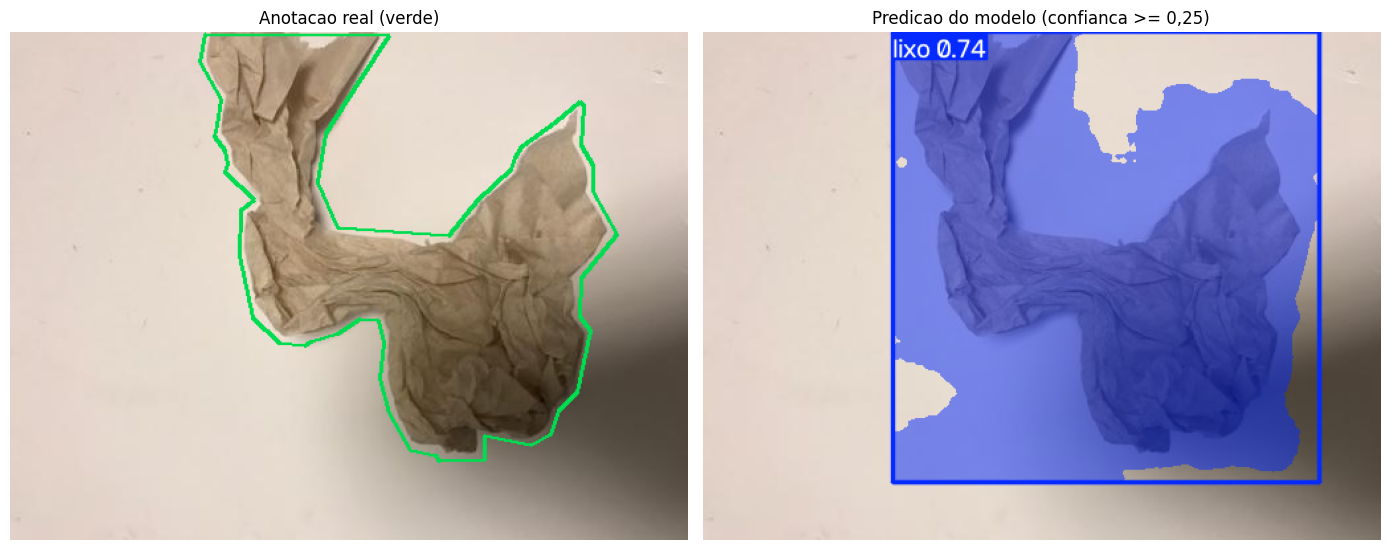

Imagem de validacao: trash_124ffb9ed194_original.jpg
Pesos usados: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\weights\best.pt
Deteccoes: 1 | IoU das mascaras: 0.559
Comparacao salva em: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao\trash_124ffb9ed194_original_comparacao.jpg
Predicao salva em: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao\trash_124ffb9ed194_original_predicao.jpg


In [11]:
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from ultralytics import YOLO

PASTA_BASE = Path.cwd()
PASTA_DATASET = PASTA_BASE / "dataset_model_yolo"
PASTA_VALIDACAO_IMAGENS = PASTA_DATASET / "images" / "val"
PASTA_VALIDACAO_LABELS = PASTA_DATASET / "labels" / "val"
CAMINHOS_PESOS = sorted(
    (PASTA_BASE / "runs" / "segment").glob("teste02_dataset_model*/weights/best.pt"),
    key=lambda caminho: caminho.stat().st_mtime,
)
PASTA_RESULTADOS_TESTE = PASTA_BASE / "runs" / "segment" / "teste02_validacao"
PASTA_RESULTADOS_TESTE.mkdir(parents=True, exist_ok=True)

if not CAMINHOS_PESOS:
    raise FileNotFoundError("Nao encontrei best.pt. Execute primeiro a celula de treinamento.")
if not PASTA_VALIDACAO_IMAGENS.is_dir() or not PASTA_VALIDACAO_LABELS.is_dir():
    raise FileNotFoundError(f"Split de validacao nao encontrado em {PASTA_DATASET}")

imagens_validacao = [
    imagem
    for imagem in sorted(PASTA_VALIDACAO_IMAGENS.glob("*.jpg"))
    if (PASTA_VALIDACAO_LABELS / f"{imagem.stem}.txt").is_file()
]
if not imagens_validacao:
    raise FileNotFoundError("Nao encontrei pares imagem-label no split de validacao.")

CAMINHO_IMAGEM_TESTE = random.Random(SEMENTE).choice(imagens_validacao)
CAMINHO_LABEL_TESTE = PASTA_VALIDACAO_LABELS / f"{CAMINHO_IMAGEM_TESTE.stem}.txt"
CAMINHO_PESOS_TESTE = CAMINHOS_PESOS[-1]
modelo_teste02 = YOLO(str(CAMINHO_PESOS_TESTE))
resultado_teste02 = modelo_teste02.predict(
    source=str(CAMINHO_IMAGEM_TESTE),
    conf=0.25,
    iou=0.7,
    device="cpu",
    verbose=False,
)[0]

imagem_original = Image.open(CAMINHO_IMAGEM_TESTE).convert("RGB")
largura, altura = imagem_original.size
mascara_real = np.zeros((altura, largura), dtype=np.uint8)
for linha in CAMINHO_LABEL_TESTE.read_text(encoding="utf-8").splitlines():
    valores = [float(valor) for valor in linha.split()]
    coordenadas = np.asarray(valores[1:], dtype=np.float32).reshape(-1, 2)
    coordenadas[:, 0] *= largura
    coordenadas[:, 1] *= altura
    cv2.fillPoly(mascara_real, [np.rint(coordenadas).astype(np.int32)], 1)

mascara_prevista = np.zeros((altura, largura), dtype=np.uint8)
if resultado_teste02.masks is not None:
    for poligono in resultado_teste02.masks.xy:
        if len(poligono) >= 3:
            cv2.fillPoly(mascara_prevista, [np.rint(poligono).astype(np.int32)], 1)

intersecao = np.logical_and(mascara_real, mascara_prevista).sum()
uniao = np.logical_or(mascara_real, mascara_prevista).sum()
iou_mascara = intersecao / uniao if uniao else float("nan")

imagem_real_anotada = imagem_original.copy()
desenho = ImageDraw.Draw(imagem_real_anotada)
for linha in CAMINHO_LABEL_TESTE.read_text(encoding="utf-8").splitlines():
    valores = [float(valor) for valor in linha.split()]
    pontos = [
        (round(valores[indice] * largura), round(valores[indice + 1] * altura))
        for indice in range(1, len(valores), 2)
    ]
    if len(pontos) >= 3:
        desenho.line(pontos + [pontos[0]], fill=(0, 220, 80), width=3)

imagem_prevista = Image.fromarray(resultado_teste02.plot()[:, :, ::-1])
CAMINHO_COMPARACAO = PASTA_RESULTADOS_TESTE / f"{CAMINHO_IMAGEM_TESTE.stem}_comparacao.jpg"
CAMINHO_PREDICAO = PASTA_RESULTADOS_TESTE / f"{CAMINHO_IMAGEM_TESTE.stem}_predicao.jpg"
resultado_teste02.save(filename=str(CAMINHO_PREDICAO))

fig, eixos = plt.subplots(1, 2, figsize=(14, 7))
eixos[0].imshow(imagem_real_anotada)
eixos[0].set_title("Anotacao real (verde)")
eixos[1].imshow(imagem_prevista)
eixos[1].set_title("Predicao do modelo (confianca >= 0,25)")
for eixo in eixos:
    eixo.axis("off")
fig.tight_layout()
fig.savefig(CAMINHO_COMPARACAO, dpi=150, bbox_inches="tight")
plt.show()

quantidade_deteccoes = 0 if resultado_teste02.boxes is None else len(resultado_teste02.boxes)
print(f"Imagem de validacao: {CAMINHO_IMAGEM_TESTE.name}")
print(f"Pesos usados: {CAMINHO_PESOS_TESTE}")
print(f"Deteccoes: {quantidade_deteccoes} | IoU das mascaras: {iou_mascara:.3f}")
print(f"Comparacao salva em: {CAMINHO_COMPARACAO}")
print(f"Predicao salva em: {CAMINHO_PREDICAO}")

In [3]:
from pathlib import Path

from ultralytics import YOLO

PASTA_BASE = Path.cwd()
PASTA_DATASET = PASTA_BASE / "dataset_model_yolo"
PASTA_VALIDACAO_IMAGENS = PASTA_DATASET / "images" / "val"
PASTA_SAIDA_VALIDACAO = PASTA_BASE / "runs" / "segment"
CAMINHOS_PESOS = sorted(
    PASTA_SAIDA_VALIDACAO.glob("teste02_dataset_model*/weights/best.pt"),
    key=lambda caminho: caminho.stat().st_mtime,
)

if not CAMINHOS_PESOS:
    raise FileNotFoundError("Nao encontrei best.pt. Execute primeiro a celula de treinamento.")
if not PASTA_VALIDACAO_IMAGENS.is_dir():
    raise FileNotFoundError(f"Pasta de validacao nao encontrada: {PASTA_VALIDACAO_IMAGENS}")

imagens_validacao = sorted(PASTA_VALIDACAO_IMAGENS.glob("*.jpg"))
CAMINHO_PESOS_TODAS_VALIDACAO = CAMINHOS_PESOS[-1]
modelo_todas_validacao = YOLO(str(CAMINHO_PESOS_TODAS_VALIDACAO))
resultados_validacao_completa = modelo_todas_validacao.val(
    data=str(PASTA_DATASET / "dataset.yaml"),
    split="val",
    imgsz=512,
    batch=4,
    workers=0,
    device="cpu",
    plots=True,
    project=str(PASTA_SAIDA_VALIDACAO),
    name="teste02_validacao_todas_metricas",
    exist_ok=True,
)

print(f"Pesos avaliados: {CAMINHO_PESOS_TODAS_VALIDACAO}")
print(f"Total de imagens no split val: {len(imagens_validacao)}")
print("Metricas no split val:")
for nome_metrica, valor in resultados_validacao_completa.results_dict.items():
    print(f"  {nome_metrica}: {valor:.4f}")

Ultralytics 8.4.182  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
WARNING val: Slow image access detected (ping: 0.2±0.1 ms, read: 46.9±42.2 MB/s, size: 62.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo\labels\val.cache... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.4it/s 4.8s0.3s
                   all         63        146      0.715      0.654      0.673      0.474      0.693      0.658      0.663      0.425
Speed: 1.3ms preprocess, 50.0ms inference, 0.0ms loss, 2.9ms postprocess per imag

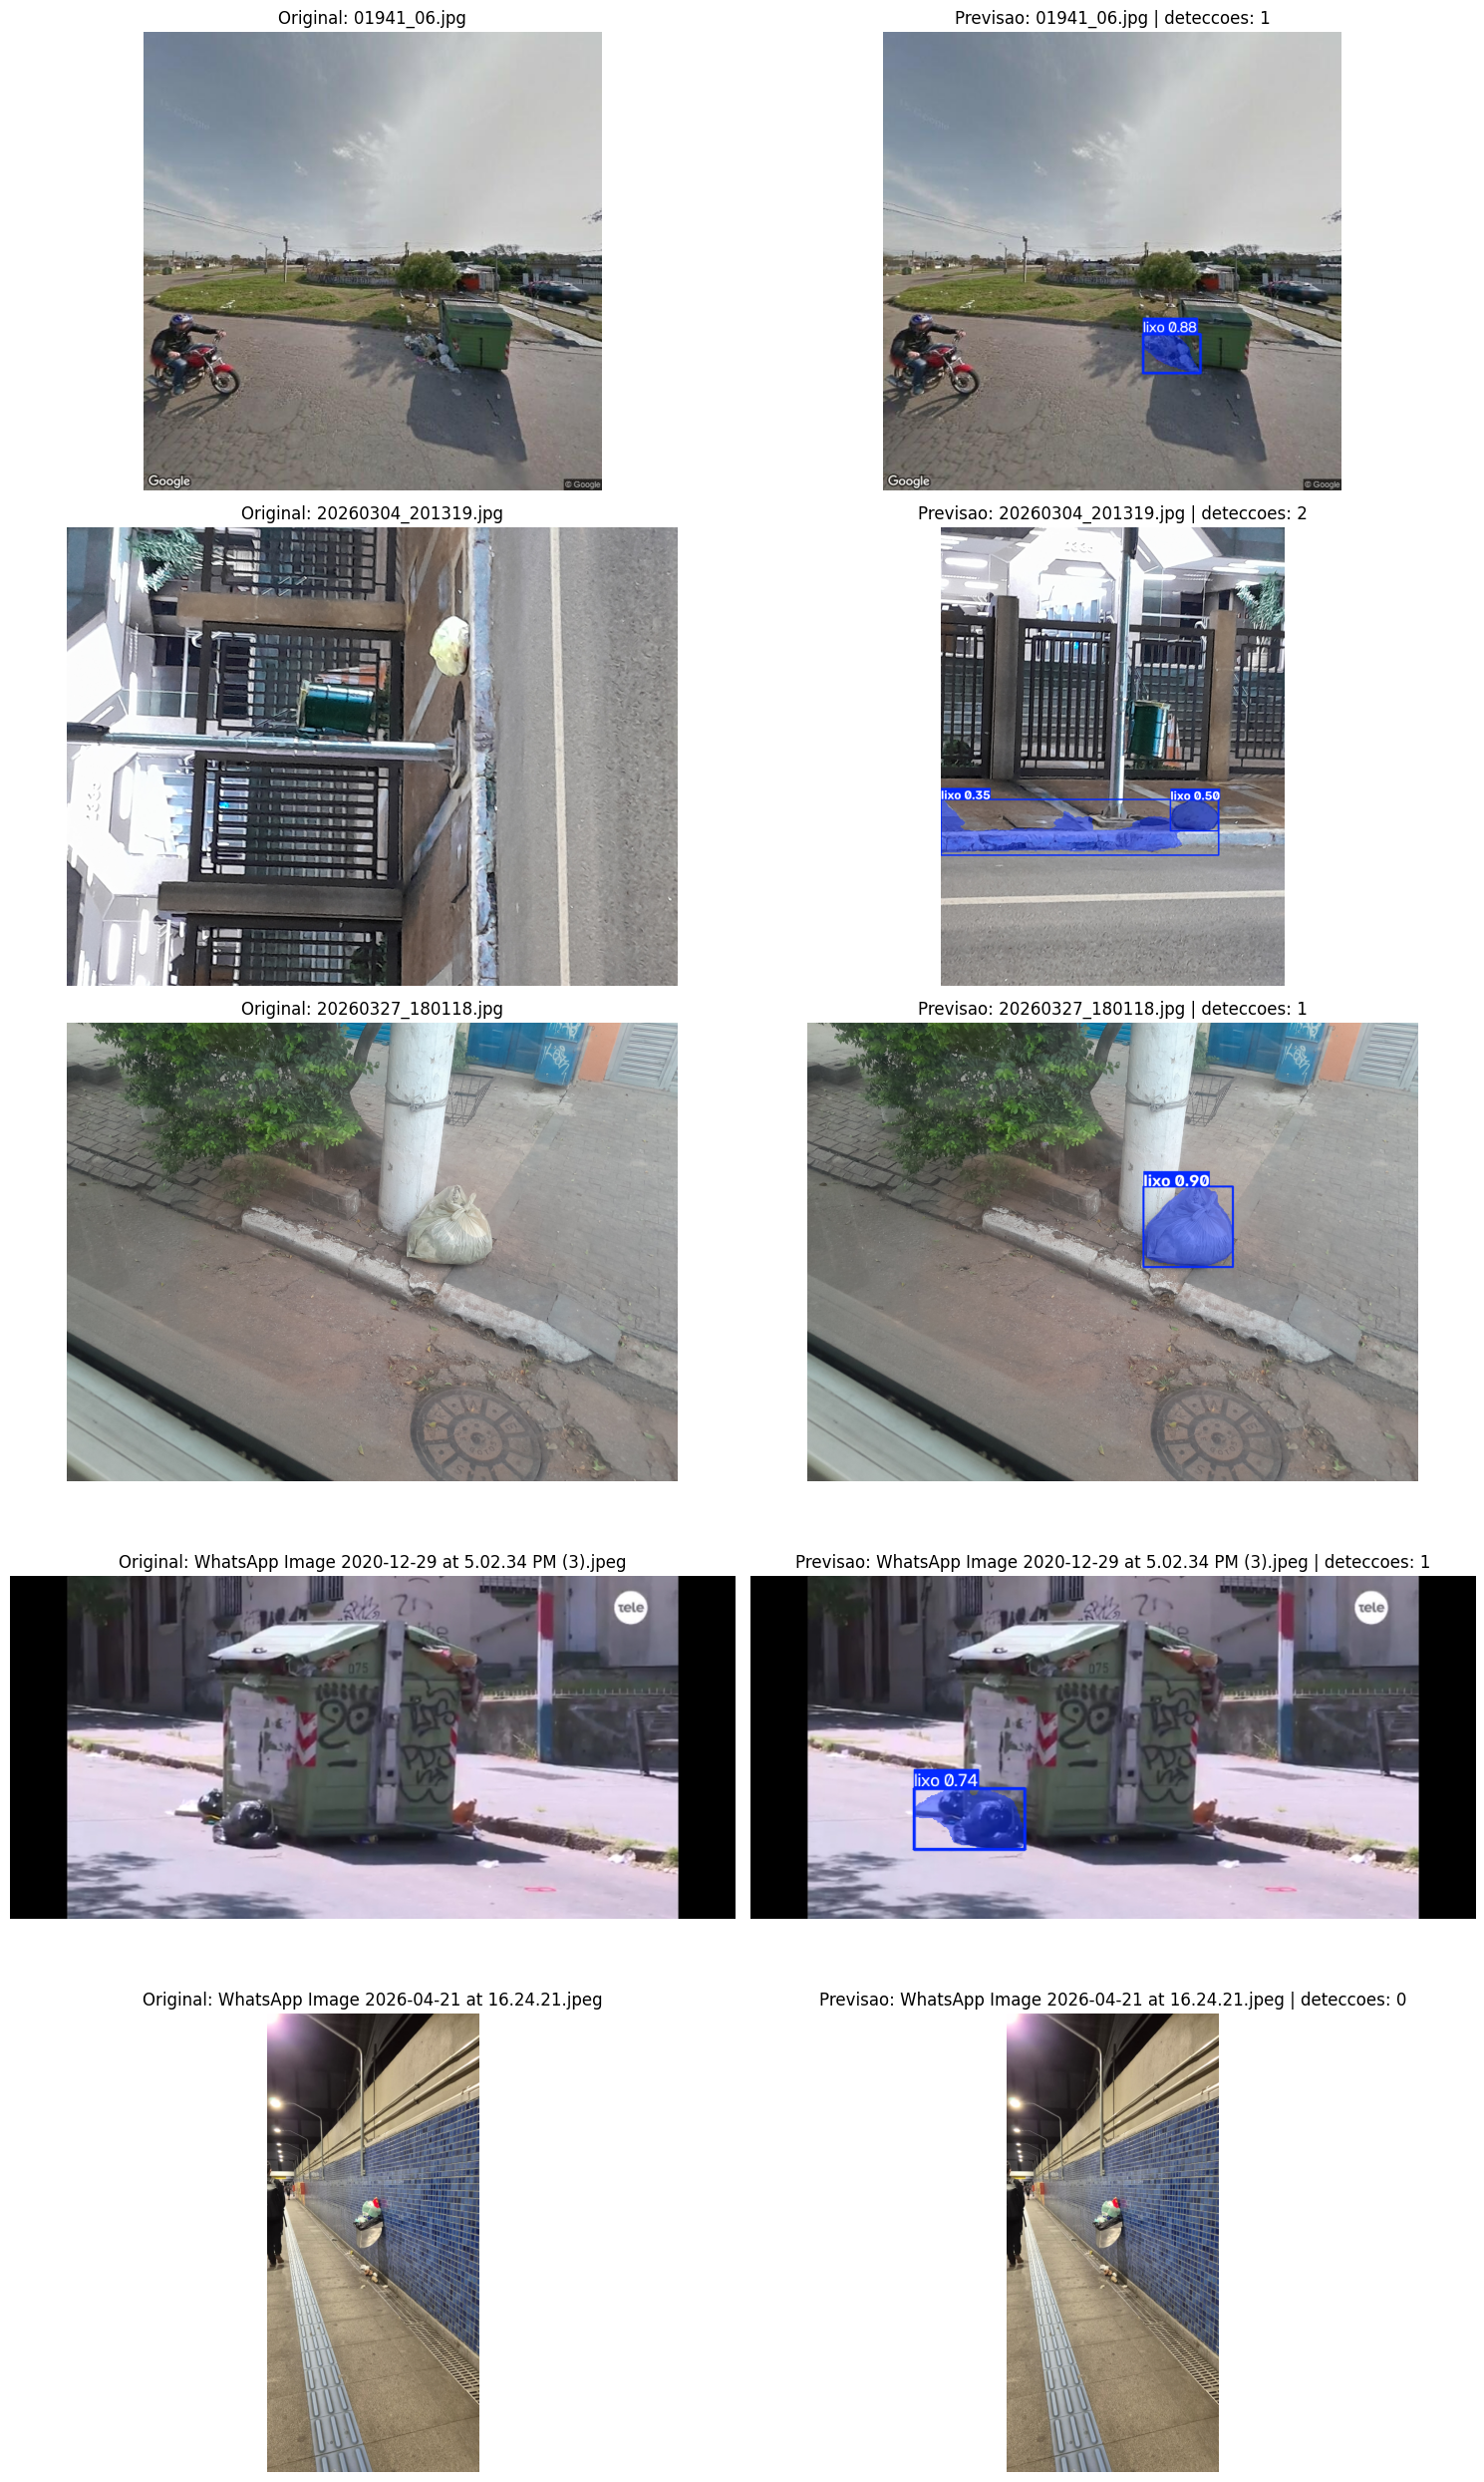

Pesos usados: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\weights\best.pt
Imagens testadas: 5
01941_06.jpg: 1 deteccao(oes) | c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao_personalizada\01941_06_predicao.jpg
20260304_201319.jpg: 2 deteccao(oes) | c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao_personalizada\20260304_201319_predicao.jpg
20260327_180118.jpg: 1 deteccao(oes) | c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao_personalizada\20260327_180118_predicao.jpg
WhatsApp Image 2020-12-29 at 5.02.34 PM (3).jpeg: 1 deteccao(oes) | c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_validacao_personalizada\WhatsApp_Image_2020-12-29_at_5_02_34_PM_3_predicao.jpg
WhatsApp Image 2026-04-21 at 16.24.21.jpeg: 0 dete

In [6]:
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PASTA_BASE = Path.cwd()
PASTA_IMAGENS_TESTE = PASTA_BASE / "validacao"
PASTA_RESULTADOS_IMAGENS_TESTE = PASTA_BASE / "runs" / "segment" / "teste02_validacao_personalizada"
EXTENSOES_IMAGEM = {".avif", ".bmp", ".gif", ".jfif", ".jpeg", ".jpg", ".png", ".tif", ".tiff", ".webp"}
CAMINHOS_PESOS = sorted(
    (PASTA_BASE / "runs" / "segment").glob("teste02_dataset_model*/weights/best.pt"),
    key=lambda caminho: caminho.stat().st_mtime,
)

if not PASTA_IMAGENS_TESTE.is_dir():
    raise FileNotFoundError(f"Pasta de imagens nao encontrada: {PASTA_IMAGENS_TESTE}")
if not CAMINHOS_PESOS:
    raise FileNotFoundError("Nao encontrei best.pt. Execute primeiro a celula de treinamento.")

imagens_para_testar = sorted(
    arquivo
    for arquivo in PASTA_IMAGENS_TESTE.rglob("*")
    if arquivo.is_file() and arquivo.suffix.lower() in EXTENSOES_IMAGEM
)
if not imagens_para_testar:
    raise FileNotFoundError(f"Nenhuma imagem encontrada em {PASTA_IMAGENS_TESTE}")

PASTA_RESULTADOS_IMAGENS_TESTE.mkdir(parents=True, exist_ok=True)
CAMINHO_PESOS_IMAGENS_TESTE = CAMINHOS_PESOS[-1]
modelo_imagens_teste = YOLO(str(CAMINHO_PESOS_IMAGENS_TESTE))
resultados_imagens_teste = []

for caminho_imagem in imagens_para_testar:
    resultado = modelo_imagens_teste.predict(
        source=str(caminho_imagem),
        conf=0.25,
        iou=0.7,
        imgsz=512,
        device="cpu",
        verbose=False,
    )[0]
    nome_saida = re.sub(r"[^A-Za-z0-9_-]+", "_", caminho_imagem.stem).strip("_")
    caminho_saida = PASTA_RESULTADOS_IMAGENS_TESTE / f"{nome_saida}_predicao.jpg"
    resultado.save(filename=str(caminho_saida))
    with Image.open(caminho_imagem) as imagem_origem:
        imagem_original = imagem_origem.convert("RGB")
    imagem_anotada = Image.fromarray(resultado.plot()[:, :, ::-1])
    quantidade = 0 if resultado.boxes is None else len(resultado.boxes)
    resultados_imagens_teste.append((caminho_imagem.name, imagem_original, imagem_anotada, quantidade, caminho_saida))
    del resultado

fig, eixos = plt.subplots(len(resultados_imagens_teste), 2, figsize=(15, 5 * len(resultados_imagens_teste)), squeeze=False)
for eixo, (nome, imagem_original, imagem_anotada, quantidade, _) in zip(eixos[:, 0], resultados_imagens_teste):
    eixo.imshow(imagem_original)
    eixo.set_title(f"Original: {nome}")
    eixo.axis("off")
for eixo, (nome, _, imagem_anotada, quantidade, _) in zip(eixos[:, 1], resultados_imagens_teste):
    eixo.imshow(imagem_anotada)
    eixo.set_title(f"Previsao: {nome} | deteccoes: {quantidade}")
    eixo.axis("off")
fig.tight_layout()
plt.show()

print(f"Pesos usados: {CAMINHO_PESOS_IMAGENS_TESTE}")
print(f"Imagens testadas: {len(resultados_imagens_teste)}")
for nome, _, _, quantidade, caminho_saida in resultados_imagens_teste:
    print(f"{nome}: {quantidade} deteccao(oes) | {caminho_saida}")